## Import Libraries

In [ ]:
# import os
# os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [3]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File handling
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


## Load CSV file

In [4]:
DATA_PATH = Path("../data/sign_mnist_train.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH.resolve()}\n"
        "Make sure sign_mnist_train.csv is inside the dataset folder."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Dataset loaded successfully!
Number of rows: 27455
Number of columns: 785


In [5]:
print("First 5 records:")
display(df.head())

print("\nLast 5 records:")
display(df.tail())

First 5 records:


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179



Last 5 records:


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
27450,13,189,189,190,190,192,193,193,193,193,...,132,165,99,77,52,200,234,200,222,225
27451,23,151,154,157,158,160,161,163,164,166,...,198,198,198,198,198,196,195,195,195,194
27452,18,174,174,174,174,174,175,175,174,173,...,121,196,209,208,206,204,203,202,200,200
27453,17,177,181,184,185,187,189,190,191,191,...,119,56,27,58,102,79,47,64,87,93
27454,23,179,180,180,180,182,181,182,183,182,...,108,132,170,194,214,203,197,205,209,215


## Data Cleaning

In [6]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nData types:")
display(df.dtypes.value_counts().rename_axis("Data Type").to_frame("Column Count"))

Dataset shape: (27455, 785)

Column names:
['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8', 'pixel9', 'pixel10', 'pixel11', 'pixel12', 'pixel13', 'pixel14', 'pixel15', 'pixel16', 'pixel17', 'pixel18', 'pixel19', 'pixel20', 'pixel21', 'pixel22', 'pixel23', 'pixel24', 'pixel25', 'pixel26', 'pixel27', 'pixel28', 'pixel29', 'pixel30', 'pixel31', 'pixel32', 'pixel33', 'pixel34', 'pixel35', 'pixel36', 'pixel37', 'pixel38', 'pixel39', 'pixel40', 'pixel41', 'pixel42', 'pixel43', 'pixel44', 'pixel45', 'pixel46', 'pixel47', 'pixel48', 'pixel49', 'pixel50', 'pixel51', 'pixel52', 'pixel53', 'pixel54', 'pixel55', 'pixel56', 'pixel57', 'pixel58', 'pixel59', 'pixel60', 'pixel61', 'pixel62', 'pixel63', 'pixel64', 'pixel65', 'pixel66', 'pixel67', 'pixel68', 'pixel69', 'pixel70', 'pixel71', 'pixel72', 'pixel73', 'pixel74', 'pixel75', 'pixel76', 'pixel77', 'pixel78', 'pixel79', 'pixel80', 'pixel81', 'pixel82', 'pixel83', 'pixel84', 'pixel85', 'pixel86', 'pixel87',

,Column Count
Data Type,
int64,785


### Check missing values

In [7]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

missing_summary = missing_summary[missing_summary["Missing Values"] > 0]

if missing_summary.empty:
    print("No missing values found.")
else:
    print("Columns containing missing values:")
    display(missing_summary)

No missing values found.


In [8]:
# Keep the original dataset unchanged for reference
df_original = df.copy()

# Identify pixel columns
pixel_cols = [col for col in df.columns if col != "label"]

# Convert columns to numeric values where possible
for col in ["label"] + pixel_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing values before cleaning:", df.isnull().sum().sum())

# Remove rows containing missing or non-numeric values
rows_before = len(df)
df = df.dropna().copy()
print("Rows removed due to missing/invalid values:", rows_before - len(df))

# Remove exact duplicate rows
duplicates_before = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)

print("Exact duplicate rows removed:", duplicates_before)

# Validate label values
valid_labels = set(range(25)) - {9}

invalid_label_mask = ~df["label"].isin(valid_labels)

print("Rows with invalid labels:", invalid_label_mask.sum())

df = df.loc[~invalid_label_mask].copy()

# Validate pixel range
pixel_values = df[pixel_cols]

invalid_pixel_mask = (
    (pixel_values < 0) | (pixel_values > 255)
).any(axis=1)

print("Rows with pixel values outside 0-255:", invalid_pixel_mask.sum())

df = df.loc[~invalid_pixel_mask].reset_index(drop=True)

# Store labels as integers
df["label"] = df["label"].astype(int)

print("\nCleaning completed.")
print("Cleaned dataset shape:", df.shape)

Missing values before cleaning: 0
Rows removed due to missing/invalid values: 0
Exact duplicate rows removed: 0
Rows with invalid labels: 0
Rows with pixel values outside 0-255: 0

Cleaning completed.
Cleaned dataset shape: (27455, 785)


In [9]:
print("Final dataset shape:", df.shape)

print("\nMissing values:", df.isnull().sum().sum())
print("Exact duplicate rows:", df.duplicated().sum())

print("\nUnique labels:")
print(sorted(df["label"].unique()))

print("\nNumber of unique classes:", df["label"].nunique())

print("\nPixel value range:")
print("Minimum pixel value:", df[pixel_cols].min().min())
print("Maximum pixel value:", df[pixel_cols].max().max())

Final dataset shape: (27455, 785)

Missing values: 0
Exact duplicate rows: 0

Unique labels:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]

Number of unique classes: 24

Pixel value range:
Minimum pixel value: 0
Maximum pixel value: 255


### Map numeric labels to alphabet letters

In [10]:
# ASL alphabet mapping
# Labels follow the alphabet order, with J left out (label 9 is never used)
# because J requires motion. Z is also excluded.

def label_to_letter(label):
    label = int(label)
    return chr(ord("A") + label)   # 0→A, 8→I, 10→K, 24→Y


# Create a mapping for all valid labels
label_mapping = {
    label: label_to_letter(label)
    for label in sorted(df["label"].unique())
}

# Sanity checks
assert 9 not in label_mapping, "Label 9 (J) should not appear in the dataset"
assert label_mapping[0] == "A" and label_mapping[10] == "K" and label_mapping[24] == "Y"

print("Label mapping:")
print(label_mapping)

# Add a readable letter column for EDA only
df["letter"] = df["label"].map(label_mapping)

display(df[["label", "letter"]].drop_duplicates().sort_values("label"))

Label mapping:
{np.int64(0): 'A', np.int64(1): 'B', np.int64(2): 'C', np.int64(3): 'D', np.int64(4): 'E', np.int64(5): 'F', np.int64(6): 'G', np.int64(7): 'H', np.int64(8): 'I', np.int64(10): 'K', np.int64(11): 'L', np.int64(12): 'M', np.int64(13): 'N', np.int64(14): 'O', np.int64(15): 'P', np.int64(16): 'Q', np.int64(17): 'R', np.int64(18): 'S', np.int64(19): 'T', np.int64(20): 'U', np.int64(21): 'V', np.int64(22): 'W', np.int64(23): 'X', np.int64(24): 'Y'}


,label,letter
46,0,A
29,1,B
2,2,C
0,3,D
44,4,E
48,5,F
1,6,G
49,7,H
6,8,I
11,10,K


## EDA

### Analyze the class distribution

In [11]:
class_counts = (
    df["label"]
    .value_counts()
    .sort_index()
    .rename_axis("label")
    .reset_index(name="image_count")
)

class_counts["letter"] = class_counts["label"].map(label_mapping)

class_counts["percentage"] = (
    class_counts["image_count"] / len(df) * 100
).round(2)

display(class_counts)

,label,image_count,letter,percentage
0,0,1126,A,4.10
1,1,1010,B,3.68
2,2,1144,C,4.17
3,3,1196,D,4.36
4,4,957,E,3.49
5,5,1204,F,4.39
6,6,1090,G,3.97
7,7,1013,H,3.69
8,8,1162,I,4.23
9,10,1114,K,4.06


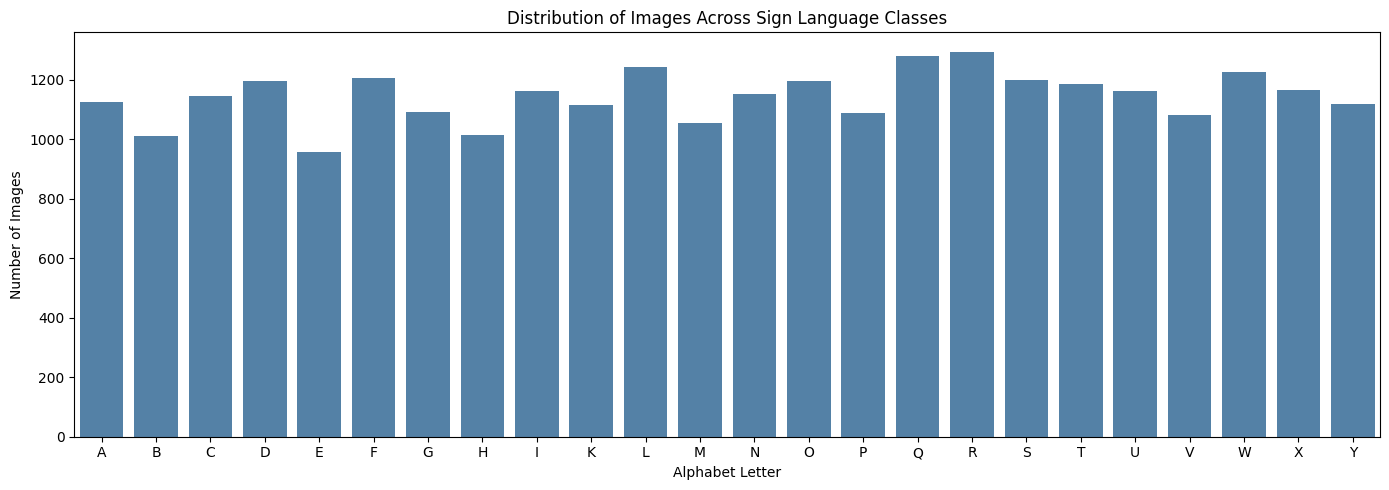

In [12]:
plt.figure(figsize=(14, 5))

sns.barplot(
    data=class_counts,
    x="letter",
    y="image_count",
    color="steelblue"
)

plt.title("Distribution of Images Across Sign Language Classes")
plt.xlabel("Alphabet Letter")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

### Display a single hand-sign image

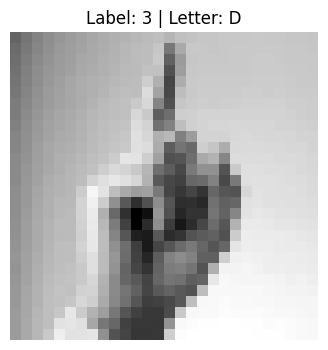

Image shape: (28, 28)
Minimum pixel value: 42
Maximum pixel value: 207


In [13]:
# Select the first image
sample = df.iloc[0]

sample_label = sample["label"]
sample_letter = sample["letter"]

sample_image = sample[pixel_cols].to_numpy(dtype=np.uint8).reshape(28, 28)

plt.figure(figsize=(4, 4))
plt.imshow(sample_image, cmap="gray")
plt.title(f"Label: {sample_label} | Letter: {sample_letter}")
plt.axis("off")
plt.show()

print("Image shape:", sample_image.shape)
print("Minimum pixel value:", sample_image.min())
print("Maximum pixel value:", sample_image.max())

### Display sample images from multiple classes

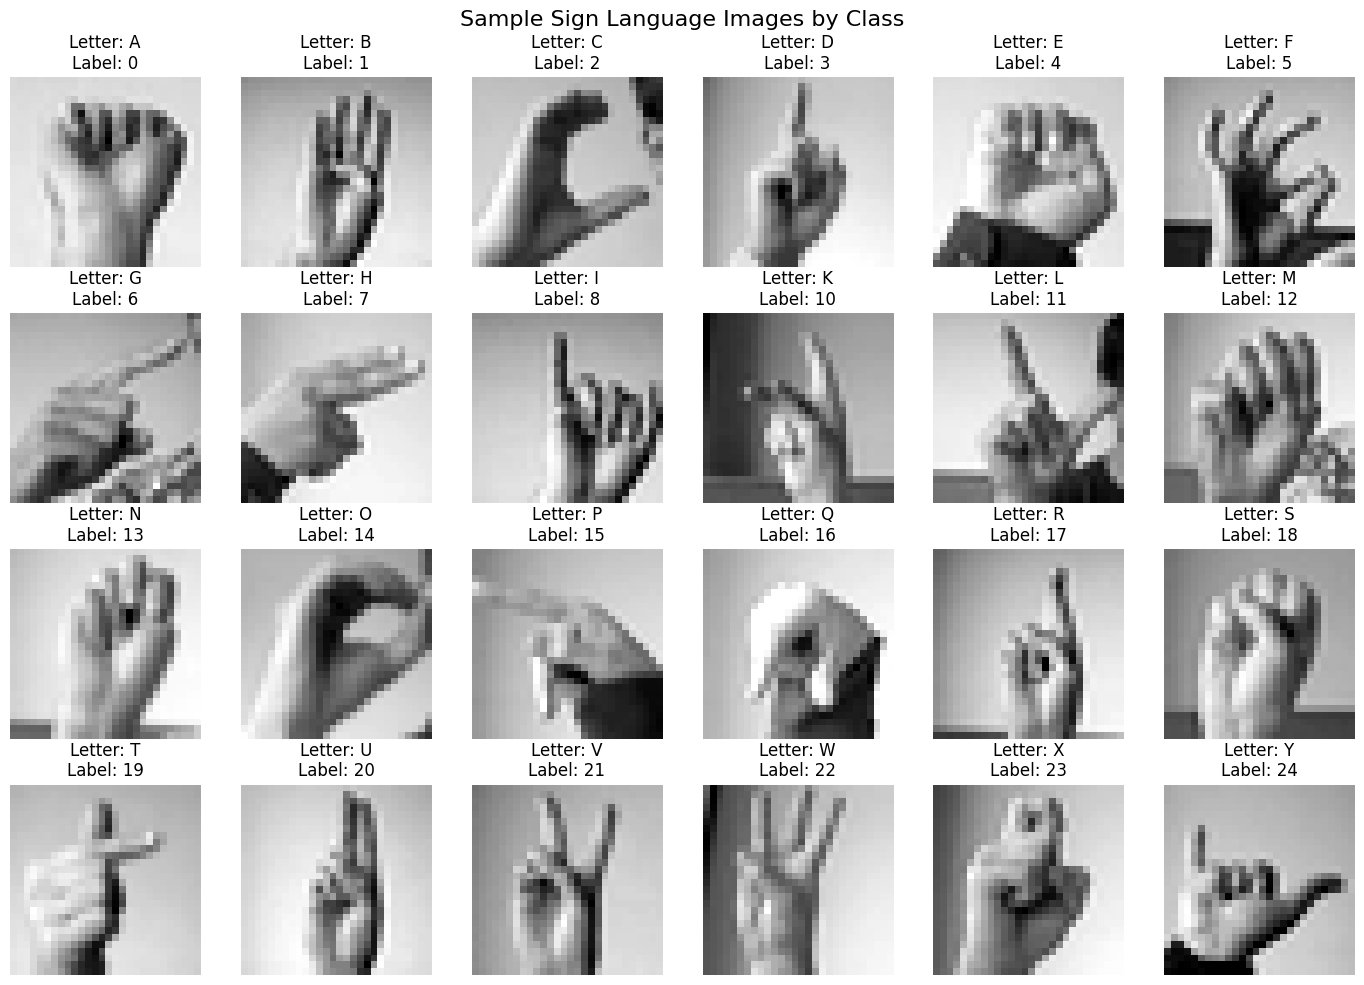

In [14]:
# Select one sample image per class
unique_classes = sorted(df["label"].unique())

fig, axes = plt.subplots(4, 6, figsize=(14, 10))
axes = axes.flatten()

for i, label in enumerate(unique_classes):
    sample = df[df["label"] == label].iloc[0]

    image = sample[pixel_cols].to_numpy(dtype=np.uint8).reshape(28, 28)
    letter = label_mapping[label]

    axes[i].imshow(image, cmap="gray")
    axes[i].set_title(f"Letter: {letter}\nLabel: {label}")
    axes[i].axis("off")

# Hide any unused axes
for i in range(len(unique_classes), len(axes)):
    axes[i].axis("off")

plt.suptitle("Sample Sign Language Images by Class", fontsize=16)
plt.tight_layout()
plt.show()

### EDA summary

In [15]:
print("=" * 50)
print("SIGN LANGUAGE DATASET — EDA SUMMARY")
print("=" * 50)

print(f"Total images: {len(df)}")
print(f"Total columns: {df.shape[1]}")
print(f"Number of classes: {df['label'].nunique()}")
print(f"Image dimensions: 28 x 28")
print(f"Pixels per image: {len(pixel_cols)}")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")
print(
    f"Pixel intensity range: "
    f"{df[pixel_cols].min().min()} to {df[pixel_cols].max().max()}"
)

print("\nClasses:")
print(", ".join(label_mapping.values()))

SIGN LANGUAGE DATASET — EDA SUMMARY
Total images: 27455
Total columns: 786
Number of classes: 24
Image dimensions: 28 x 28
Pixels per image: 784
Missing values: 0
Duplicate rows: 0
Pixel intensity range: 0 to 255

Classes:
A, B, C, D, E, F, G, H, I, K, L, M, N, O, P, Q, R, S, T, U, V, W, X, Y


## Data Preprocessing

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

print("Preprocessing libraries imported successfully!")
print("PyTorch version:", torch.__version__)

Preprocessing libraries imported successfully!
PyTorch version: 2.14.1+cu130


### Separate features and labels

In [17]:

# Input features: pixel values only
X = df[pixel_cols].to_numpy(dtype=np.float32)

# Preserve the original labels
y_original = df["label"].to_numpy(dtype=np.int64)

# Map original labels (0-8, 10-24) to contiguous indices (0-23)
original_labels = sorted(np.unique(y_original))

original_to_class = {
    original_label: class_index
    for class_index, original_label in enumerate(original_labels)
}

class_to_original = {
    class_index: original_label
    for original_label, class_index in original_to_class.items()
}

# Use remapped labels for training
y = np.array(
    [original_to_class[label] for label in y_original],
    dtype=np.int64
)

# Preserve the correct alphabet mapping for model predictions
class_to_letter = {
    class_index: label_mapping[original_label]
    for class_index, original_label in class_to_original.items()
}

print("Features shape:", X.shape)
print("Original labels:", sorted(np.unique(y_original)))
print("Remapped labels:", sorted(np.unique(y)))
print("Number of classes:", len(class_to_letter))
print("Class-to-letter mapping:", class_to_letter)

assert sorted(np.unique(y)) == list(range(24))


Features shape: (27455, 784)
Original labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]
Remapped labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]
Number of classes: 24
Class-to-letter mapping: {0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'E', 5: 'F', 6: 'G', 7: 'H', 8: 'I', 9: 'K', 10: 'L', 11: 'M', 12: 'N', 13: 'O', 14: 'P', 15: 'Q', 16: 'R', 17: 'S', 18: 'T', 19: 'U', 20: 'V', 21: 'W', 22: 'X', 23: 'Y'}


### Reshape pixels into images

In [18]:
# Reshape: (samples, pixels) -> (samples, height, width)
X_images = X.reshape(-1, 28, 28)

print("Reshaped image data:", X_images.shape)
print("Single image shape:", X_images[0].shape)

Reshaped image data: (27455, 28, 28)
Single image shape: (28, 28)


### Normalize pixel values

In [19]:
X_images = X_images / 255.0

print("Minimum normalized pixel:", X_images.min())
print("Maximum normalized pixel:", X_images.max())
print("Mean normalized pixel:", X_images.mean())

Minimum normalized pixel: 0.0
Maximum normalized pixel: 1.0
Mean normalized pixel: 0.6246706


### Add the CNN channel dimension
PyTorch CNNs expect grayscale images in the format:

(number_of_images, channels, height, width)

Because these are grayscale images, the channel count is 1.

In [20]:
X_images = np.expand_dims(X_images, axis=1)

print("CNN input shape:", X_images.shape)

CNN input shape: (27455, 1, 28, 28)


### Split into training and validation sets

In [21]:
X_train, X_val, y_train, y_val = train_test_split(
    X_images,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Validation images:", X_val.shape)
print("Validation labels:", y_val.shape)

Training images: (21964, 1, 28, 28)
Training labels: (21964,)
Validation images: (5491, 1, 28, 28)
Validation labels: (5491,)


### Convert data to PyTorch tensors

In [22]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

print("Training tensor shape:", X_train_tensor.shape)
print("Training label tensor shape:", y_train_tensor.shape)

print("Validation tensor shape:", X_val_tensor.shape)
print("Validation label tensor shape:", y_val_tensor.shape)

Training tensor shape: torch.Size([21964, 1, 28, 28])
Training label tensor shape: torch.Size([21964])
Validation tensor shape: torch.Size([5491, 1, 28, 28])
Validation label tensor shape: torch.Size([5491])


### Create PyTorch datasets and DataLoaders

In [23]:
BATCH_SIZE = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 344
Validation batches: 86


### Select the compute device

In [24]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Selected device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


# Model Training

## Pre-Trained Model Setup

### Config and imports

In [23]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from torchvision.models import ResNet50_Weights, EfficientNet_B0_Weights

NUM_CLASSES = 24
IMG_SIZE = 224

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

### Input adapter function

In [24]:
def prepare_batch(x):
    # x: (B, 1, 28, 28), values in [0, 1], may be on CPU or GPU
    x = x.to(device)
    x = F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
    x = x.repeat(1, 3, 1, 1)  # grayscale -> 3 channels
    return (x - IMAGENET_MEAN) / IMAGENET_STD

### Model builders and freezing

In [25]:
def build_model(name, num_classes=NUM_CLASSES):
    if name == "resnet50":
        m = models.resnet50(weights=ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    else:
        raise ValueError(f"Unknown model: {name}")
    return m.to(device)


def freeze_backbone(model, name):
    """Freeze everything except the new classification head."""
    head = model.fc if name == "resnet50" else model.classifier
    for p in model.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True


def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

### Build and sanity check both models

In [26]:
for name in ["efficientnet_b0", "resnet50"]:
    model = build_model(name)
    freeze_backbone(model, name)

    print(f"\n{name}")
    print(f"  Trainable parameters (head only): {count_trainable(model):,}")

    xb, _ = next(iter(train_loader))
    xb8 = prepare_batch(xb[:8])

    model.eval()
    with torch.no_grad():
        out = model(xb8)

    print(f"  Input to model: {tuple(xb8.shape)}")
    print(f"  Output logits:  {tuple(out.shape)}")  # expect (8, 24)
    print(f"  Model device:   {next(model.parameters()).device}")

    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()


efficientnet_b0
  Trainable parameters (head only): 30,744
  Input to model: (8, 3, 224, 224)
  Output logits:  (8, 24)
  Model device:   cuda:0

resnet50
  Trainable parameters (head only): 49,176
  Input to model: (8, 3, 224, 224)
  Output logits:  (8, 24)
  Model device:   cuda:0


# EfficientNetB0

## Loss, optimizer, and training

In [27]:
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    """One pass over a loader. Trains if an optimizer is given, otherwise evaluates."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, total = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(prepare_batch(xb))
            loss = criterion(logits, yb)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)

    return total_loss / total, correct / total


def train_head(name, epochs=5, lr=1e-3):
    model = build_model(name)
    freeze_backbone(model, name)

    # Give Adam only the parameters that are trainable
    optimizer = torch.optim.Adam(
        (p for p in model.parameters() if p.requires_grad), lr=lr
    )

    best_acc, best_state = 0.0, None
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader)
        print(f"Epoch {epoch}/{epochs} | "
              f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f}")

        if va_acc > best_acc:
            best_acc = va_acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    print(f"\nBest validation accuracy: {best_acc:.4f}")
    return model, best_acc


effnet_head, effnet_head_acc = train_head("efficientnet_b0", epochs=5, lr=1e-3)

Epoch 1/5 | train loss 1.2190 acc 0.7663 | val loss 0.4312 acc 0.9426
Epoch 2/5 | train loss 0.4414 acc 0.9239 | val loss 0.2070 acc 0.9778
Epoch 3/5 | train loss 0.2984 acc 0.9466 | val loss 0.1238 acc 0.9860
Epoch 4/5 | train loss 0.2302 acc 0.9563 | val loss 0.0914 acc 0.9891
Epoch 5/5 | train loss 0.1927 acc 0.9624 | val loss 0.0755 acc 0.9891

Best validation accuracy: 0.9891


## fine-tuning (EfficientNetB0)

In [28]:
# Save phase 1 weights as a safety checkpoint
torch.save(effnet_head.state_dict(), "effnet_phase1.pt")


def unfreeze_last_blocks(model, name, n_blocks=2):
    """Freeze everything, then unfreeze the last n blocks and the head."""
    for p in model.parameters():
        p.requires_grad = False

    if name == "efficientnet_b0":
        blocks = list(model.features)[-n_blocks:]
        head = model.classifier
    else:  # resnet50
        blocks = [model.layer4] if n_blocks <= 1 else [model.layer3, model.layer4]
        head = model.fc

    for b in blocks:
        for p in b.parameters():
            p.requires_grad = True
    for p in head.parameters():
        p.requires_grad = True


def fine_tune(model, name, epochs=3, lr=1e-5, n_blocks=2):
    unfreeze_last_blocks(model, name, n_blocks)
    print(f"Trainable parameters: {count_trainable(model):,}")

    optimizer = torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad], lr=lr
    )

    best_acc, best_state = 0.0, None
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader)
        print(f"Epoch {epoch}/{epochs} | "
              f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f}")

        if va_acc > best_acc:
            best_acc = va_acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    print(f"\nBest validation accuracy after fine-tuning: {best_acc:.4f}")
    return model, best_acc


effnet_ft, effnet_ft_acc = fine_tune(effnet_head, "efficientnet_b0", epochs=3, lr=1e-5)

Trainable parameters: 1,160,136
Epoch 1/3 | train loss 0.1753 acc 0.9684 | val loss 0.0669 acc 0.9920
Epoch 2/3 | train loss 0.1410 acc 0.9737 | val loss 0.0493 acc 0.9956
Epoch 3/3 | train loss 0.1224 acc 0.9768 | val loss 0.0374 acc 0.9973

Best validation accuracy after fine-tuning: 0.9973


## Evaluation of EfficientNetB0

Overall accuracy: 0.9973

Per-class metrics:
              precision    recall  f1-score   support

           A     0.9956    1.0000    0.9978       225
           B     0.9951    1.0000    0.9975       202
           C     1.0000    1.0000    1.0000       229
           D     0.9876    1.0000    0.9938       239
           E     0.9896    1.0000    0.9948       191
           F     1.0000    1.0000    1.0000       241
           G     0.9954    0.9954    0.9954       218
           H     1.0000    1.0000    1.0000       203
           I     1.0000    0.9957    0.9978       232
           K     1.0000    0.9910    0.9955       223
           L     1.0000    0.9960    0.9980       248
           M     0.9906    1.0000    0.9953       211
           N     1.0000    0.9826    0.9912       230
           O     1.0000    1.0000    1.0000       239
           P     1.0000    1.0000    1.0000       218
           Q     1.0000    1.0000    1.0000       256
           R     1.0000    0.9961   

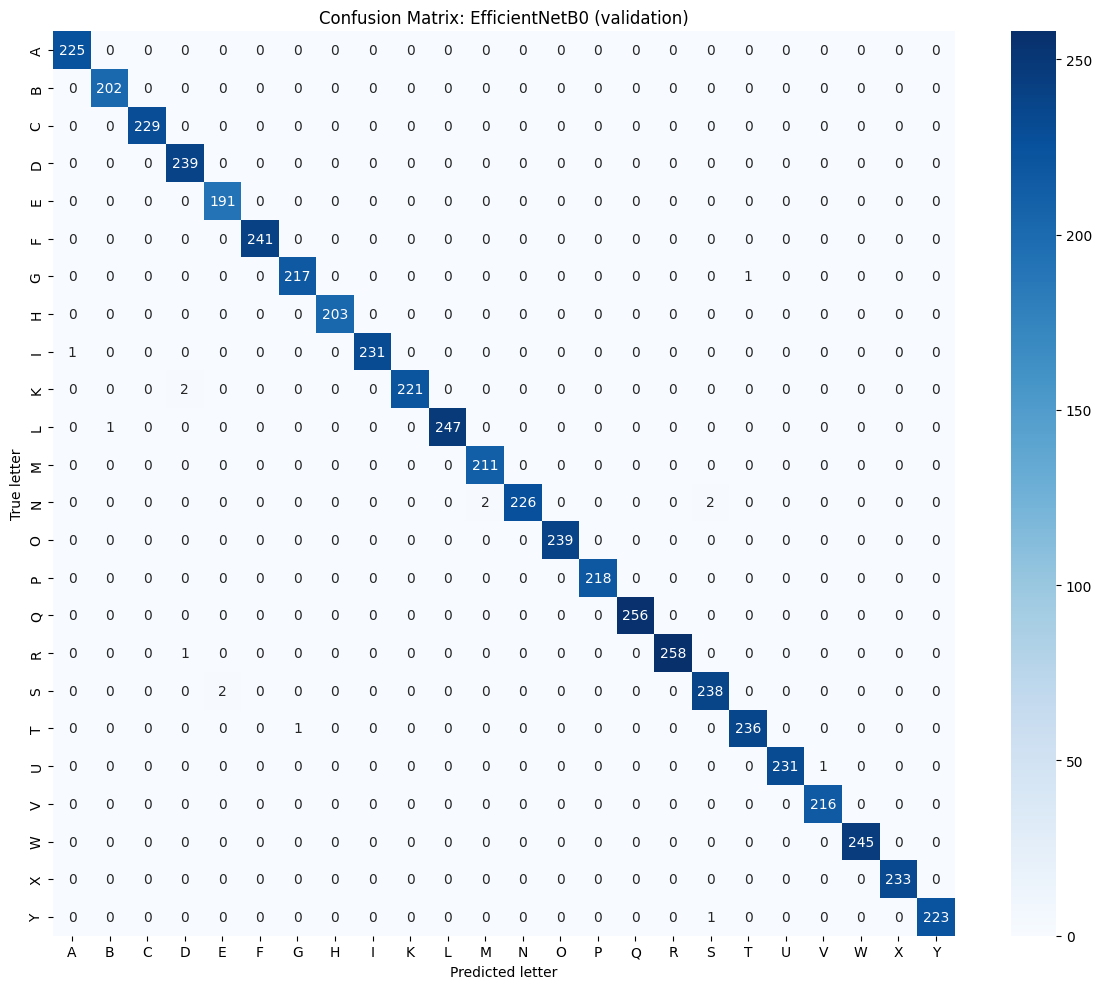


Most frequent confusions:
  S predicted as E: 2 times
  K predicted as D: 2 times
  N predicted as M: 2 times
  N predicted as S: 2 times
  R predicted as D: 1 times


In [29]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Save the final EfficientNetB0 weights
torch.save(effnet_ft.state_dict(), "effnet_final.pt")


@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, labels = [], []
    for xb, yb in loader:
        logits = model(prepare_batch(xb.to(device)))
        preds.append(logits.argmax(dim=1).cpu())
        labels.append(yb)
    return torch.cat(labels).numpy(), torch.cat(preds).numpy()


y_true, y_pred = predict(effnet_ft, val_loader)
print("Overall accuracy:", round(accuracy_score(y_true, y_pred), 4))

target_names = [class_to_letter[i] for i in range(NUM_CLASSES)]
print("\nPer-class metrics:")
print(classification_report(y_true, y_pred, target_names=target_names, digits=4))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Predicted letter")
plt.ylabel("True letter")
plt.title("Confusion Matrix: EfficientNetB0 (validation)")
plt.tight_layout()
plt.show()

# Most common mistakes (off-diagonal cells)
off = cm.copy()
np.fill_diagonal(off, 0)
top = np.argsort(-off.ravel())[:5]
print("\nMost frequent confusions:")
for idx in top:
    i, j = np.unravel_index(idx, off.shape)
    print(f"  {target_names[i]} predicted as {target_names[j]}: {off[i, j]} times")

# ResNet50

## Training ResNet50 with the same above two phases

In [30]:
# Phase 1: head only
resnet_head, resnet_head_acc = train_head("resnet50", epochs=5, lr=1e-3)
torch.save(resnet_head.state_dict(), "resnet_phase1.pt")

# Phase 2: fine-tune the last two blocks
resnet_ft, resnet_ft_acc = fine_tune(resnet_head, "resnet50", epochs=3, lr=1e-5)
torch.save(resnet_ft.state_dict(), "resnet_final.pt")

Epoch 1/5 | train loss 1.4335 acc 0.7474 | val loss 0.7459 acc 0.9144
Epoch 2/5 | train loss 0.5143 acc 0.9421 | val loss 0.3679 acc 0.9554
Epoch 3/5 | train loss 0.3058 acc 0.9700 | val loss 0.2538 acc 0.9730
Epoch 4/5 | train loss 0.2090 acc 0.9831 | val loss 0.1890 acc 0.9798
Epoch 5/5 | train loss 0.1547 acc 0.9894 | val loss 0.1411 acc 0.9854

Best validation accuracy: 0.9854
Trainable parameters: 22,112,280
Epoch 1/3 | train loss 0.0349 acc 0.9974 | val loss 0.0145 acc 0.9978
Epoch 2/3 | train loss 0.0059 acc 0.9998 | val loss 0.0071 acc 0.9987
Epoch 3/3 | train loss 0.0026 acc 0.9999 | val loss 0.0044 acc 0.9993

Best validation accuracy after fine-tuning: 0.9993


## Evaluation of ResNet50

Overall accuracy: 0.9993

Per-class metrics:
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       225
           B     1.0000    1.0000    1.0000       202
           C     1.0000    1.0000    1.0000       229
           D     0.9958    1.0000    0.9979       239
           E     1.0000    1.0000    1.0000       191
           F     1.0000    0.9959    0.9979       241
           G     1.0000    1.0000    1.0000       218
           H     1.0000    1.0000    1.0000       203
           I     1.0000    1.0000    1.0000       232
           K     1.0000    1.0000    1.0000       223
           L     1.0000    1.0000    1.0000       248
           M     0.9953    1.0000    0.9976       211
           N     1.0000    0.9957    0.9978       230
           O     1.0000    1.0000    1.0000       239
           P     1.0000    1.0000    1.0000       218
           Q     1.0000    1.0000    1.0000       256
           R     1.0000    0.9961   

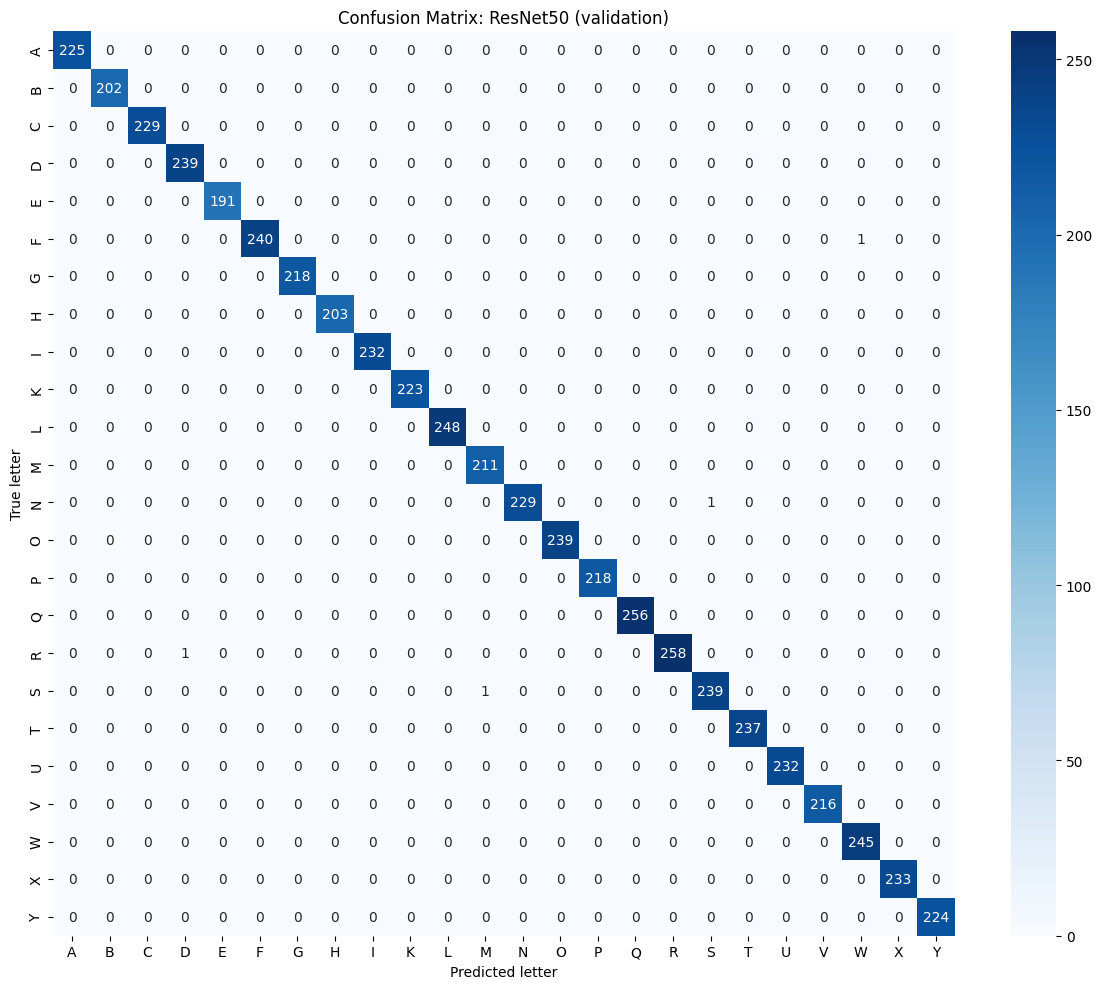


Most frequent confusions:
  S predicted as M: 1 times
  R predicted as D: 1 times
  N predicted as S: 1 times
  F predicted as W: 1 times
  Y predicted as Y: 0 times


In [31]:
y_true, y_pred = predict(resnet_ft, val_loader)
print("Overall accuracy:", round(accuracy_score(y_true, y_pred), 4))

target_names = [class_to_letter[i] for i in range(NUM_CLASSES)]
print("\nPer-class metrics:")
print(classification_report(y_true, y_pred, target_names=target_names, digits=4))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Predicted letter")
plt.ylabel("True letter")
plt.title("Confusion Matrix: ResNet50 (validation)")
plt.tight_layout()
plt.show()

# Most common mistakes (off-diagonal cells)
off = cm.copy()
np.fill_diagonal(off, 0)
top = np.argsort(-off.ravel())[:5]
print("\nMost frequent confusions:")
for idx in top:
    i, j = np.unravel_index(idx, off.shape)
    print(f"  {target_names[i]} predicted as {target_names[j]}: {off[i, j]} times")

# Model Comparison

## EfficientNetB0 vs ResNet50
This cell measures accuracy, macro F1, total parameter count, and inference time per image for both models. 
The timing uses the GPU and synchronizes it so the measurement is accurate.

In [32]:
import time
from sklearn.metrics import f1_score

def evaluate_model(model, name):
    y_true, y_pred = predict(model, val_loader)
    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    total_params = sum(p.numel() for p in model.parameters())

    # Inference timing on one batch of 64 images, after warm-up
    xb, _ = next(iter(val_loader))
    xb = prepare_batch(xb)
    model.eval()
    with torch.no_grad():
        for _ in range(3):  # warm-up runs
            model(xb)
        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(10):
            model(xb)
        if device.type == "cuda":
            torch.cuda.synchronize()
        elapsed = time.perf_counter() - t0

    return {
        "model": name,
        "val_accuracy": round(acc, 4),
        "macro_f1": round(macro_f1, 4),
        "total_params_M": round(total_params / 1e6, 2),
        "ms_per_image": round(elapsed / 10 / xb.size(0) * 1000, 3),
    }


results = pd.DataFrame([
    evaluate_model(effnet_ft, "EfficientNetB0"),
    evaluate_model(resnet_ft, "ResNet50"),
])
display(results)

,model,val_accuracy,macro_f1,total_params_M,ms_per_image
0,EfficientNetB0,0.9973,0.9972,4.04,1.363
1,ResNet50,0.9993,0.9993,23.56,2.970


## Saving the ResNet model and its label mapping

In [33]:
import json
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save the trained model with everything inference needs
checkpoint_path = MODEL_DIR / "resnet50_sign_classifier.pt"
torch.save({
    "model_name": "resnet50",
    "state_dict": resnet_ft.state_dict(),
    "num_classes": NUM_CLASSES,
    "img_size": IMG_SIZE,
    "imagenet_mean": [0.485, 0.456, 0.406],
    "imagenet_std": [0.229, 0.224, 0.225],
    "class_to_letter": class_to_letter,
    "val_accuracy": float(resnet_ft_acc),
}, checkpoint_path)

# 2. Save the label mapping as JSON for reference and for the app
labels_path = MODEL_DIR / "labels.json"
with open(labels_path, "w") as f:
    json.dump({
        "class_index_to_letter": {str(k): v for k, v in class_to_letter.items()},
        "class_index_to_original_label": {str(k): int(v) for k, v in class_to_original.items()},
    }, f, indent=2)

print("Saved:", checkpoint_path.resolve())
print("Saved:", labels_path.resolve())

Saved: C:\Users\rishi\DS\Deep Learning\Sign Language Detection\models\resnet50_sign_classifier.pt
Saved: C:\Users\rishi\DS\Deep Learning\Sign Language Detection\models\labels.json


In [34]:
# Reload the model from the checkpoint and verify that it works correctly
ckpt = torch.load(checkpoint_path, map_location=device)

reloaded = build_model(ckpt["model_name"])
reloaded.load_state_dict(ckpt["state_dict"])
reloaded.eval()

y_true, y_pred = predict(reloaded, val_loader)
print("Reloaded validation accuracy:", round(accuracy_score(y_true, y_pred), 4))

Reloaded validation accuracy: 0.9993


# Check the predictor on validation images

In [ ]:
import sys
sys.path.append("..")

from PIL import Image
from src.inference.predictor import SignPredictor

predictor = SignPredictor("../models/resnet50_sign_classifier.pt")

# 1. Quick visual check: 8 validation images
imgs = [Image.fromarray((X_val[i, 0] * 255).astype(np.uint8)) for i in range(8)]
true_letters = [class_to_letter[int(y_val[i])] for i in range(8)]

print("Quick check (8 images):")
for pred, true in zip(predictor.predict(imgs), true_letters):
    status = "OK " if pred["letter"] == true else "MISS"
    print(f"  {status} true={true}  predicted={pred['letter']}  conf={pred['confidence']:.3f}")

# 2. Accuracy on 500 validation images through the same predictor path
N = 500
imgs = [Image.fromarray((X_val[i, 0] * 255).astype(np.uint8)) for i in range(N)]
true_idx = y_val[:N]
preds = predictor.predict(imgs)
pred_letters = [p["letter"] for p in preds]
true_letters = [class_to_letter[int(i)] for i in true_idx]

acc = np.mean([p == t for p, t in zip(pred_letters, true_letters)])
print(f"\nPredictor accuracy on {N} validation images: {acc:.4f}")

Quick check (8 images):
  OK  true=T  predicted=T  conf=0.998
  OK  true=N  predicted=N  conf=0.986
  OK  true=N  predicted=N  conf=0.992
  OK  true=X  predicted=X  conf=0.998
  OK  true=V  predicted=V  conf=0.999
  OK  true=C  predicted=C  conf=1.000
  OK  true=G  predicted=G  conf=0.996
  OK  true=O  predicted=O  conf=0.999


c:\Users\rishi\miniconda3\envs\ds-env\Lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '



Predictor accuracy on 500 validation images: 0.9920


# Check Translator

In [36]:
from src.translation.translator import Translator, LANGUAGES

translator = Translator(device=device)

test_words = ["HELLO", "THANK YOU", "WATER", "FRIEND"]
targets = list(LANGUAGES.values())

for word in test_words:
    result = translator.translate(word, targets)
    print(f"\n{word}")
    for name, code in LANGUAGES.items():
        print(f"  {name:8s}: {result[code]}")

c:\Users\rishi\miniconda3\envs\ds-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 512/512 [00:00<00:00, 30114.76it/s]
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer 


HELLO
  Tamil   : வணக்கம்
  Hindi   : नमस्कार
  French  : Bonjour !
  Spanish : Hola , ¿ qué pasa ?
  German  : Hallo , das ist alles .


[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/


THANK YOU
  Tamil   : நன்றி
  Hindi   : धन्यवाद
  French  : Merci beaucoup.
  Spanish : Gracias .
  German  : Danke .


[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/


WATER
  Tamil   : நீர்
  Hindi   : पानी
  French  : L'eau
  Spanish : Agua
  German  : Wasser


[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



FRIEND
  Tamil   : நண்பர்
  Hindi   : मित्र
  French  : Un ami
  Spanish : Amigo
  German  : Freund


# Testing Images from Validation Set

In [37]:
from pathlib import Path
from PIL import Image
import numpy as np

out_dir = Path("../test_images")
out_dir.mkdir(exist_ok=True)

for i in range(3):
    arr = (X_val[i, 0] * 255).astype(np.uint8)
    letter = class_to_letter[int(y_val[i])]
    Image.fromarray(arr).save(out_dir / f"val_{letter}_{i}.png")
    print("Saved", out_dir / f"val_{letter}_{i}.png")

Saved ..\test_images\val_T_0.png
Saved ..\test_images\val_N_1.png
Saved ..\test_images\val_N_2.png


Original size: (148, 187)


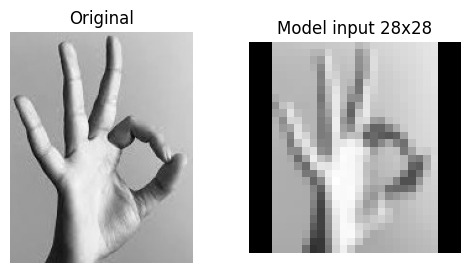

In [28]:
img = Image.open("../data/sign2.jpg")
print("Original size:", img.size)

x = SignPredictor.to_training_format(predictor, img)  # uses the predictor's own preprocessing
plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1); plt.imshow(img.convert("L"), cmap="gray"); plt.title("Original"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(x[0, 0].numpy(), cmap="gray"); plt.title("Model input 28x28"); plt.axis("off")
plt.show()